# Prototype E: do states with more data centers have faster rising electricity prices?
**Question:** Residents often say data centers will raise their electric bills. At the state level, did residential prices rise faster where there are more data centers?

**Data:** EIA Form 861 residential revenue and sales by state, 2018 to 2025, in 2025 dollars (BLS CPI-U). Data centers from the project database, counted per million residents (Census PEP 2025).

**Design:** a scatter of states (data centers per million residents vs. real price change, 2019 to 2025), linked to a line chart of each state's price over time. Brushing states on the scatter draws their price lines next to the U.S. average. Orange marks states where most residential customers are served by utilities in the PJM grid, which links this chart to prototype F.

**What this can show:** whether high data center states stand out on price, and which states drive any pattern.
**What it can't:** cause. State prices move with fuel costs, wildfire and storm costs, transmission spending and rate cases, so a state can rank high on both without one causing the other.

Caveats carried onto the page:
- The database has no build date for most facilities, so the x axis is how many data centers a state has now (operating plus planned), not growth over time.
- Facility counts treat a small server room and a 1 GW campus the same. MW is reported for only 40% of rows, too few to use here.
- Prices are annual averages (revenue divided by kWh). The PJM capacity jump reached bills in June 2025, so 2025 only partly shows it.
- Planned facilities count toward the x axis even though they cannot have affected past prices; the operating-only count is in the table below.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name in ("data", "jppolizzi", "pnidadavolu", "sgarimella") else Path.cwd()
sys.path[:0] = [str(ROOT / ".pylibs"), str(ROOT / "scripts")]
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
CLEAN = ROOT / "data" / "clean"

# Same palette as prototypes C and D.
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a9a89f"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": SURF, "axes.facecolor": SURF})
s = pd.read_csv(CLEAN / "eia861_state_residential.csv")
d = pd.read_csv(CLEAN / "datacenters.csv")
c = pd.read_csv(CLEAN / "counties.csv", dtype={"geoid": str})
u = pd.read_csv(CLEAN / "eia861_utility_sales.csv")
cpi = pd.read_csv(CLEAN / "cpi_annual.csv").set_index("year")["deflator_to_2025"]
BASE, END = 2019, 2025

pop = c.groupby("state")["pop_2025"].sum()
names = c.drop_duplicates("state").set_index("state")["state_name"]
live = d[d.status_group.isin(["operating", "pipeline"])]
n_all = live.groupby("state").size()
n_op = d[d.status_group == "operating"].groupby("state").size()

# PJM share: share of a state's residential customers whose utility sits in the PJM balancing authority (2025).
r25 = u[u.year == END]
pjm_share = r25[r25.ba_code == "PJM"].groupby("state")["res_customers"].sum() / r25.groupby("state")["res_customers"].sum()

w = s.pivot(index="state", columns="year", values="res_price_cents_kwh_real2025")
t = pd.DataFrame({
    "state_name": names,
    "pop_m": pop / 1e6,
    "dc_live": n_all, "dc_operating": n_op,
    "price_2019": w[BASE], "price_2025": w[END],
    "pjm_share": pjm_share,
}).loc[w.index]
t[["dc_live", "dc_operating", "pjm_share"]] = t[["dc_live", "dc_operating", "pjm_share"]].fillna(0)
t["dc_per_m"] = t.dc_live / t.pop_m
t["dc_op_per_m"] = t.dc_operating / t.pop_m
t["price_change_pct"] = (t.price_2025 / t.price_2019 - 1) * 100
t["pjm"] = t.pjm_share > 0.5
print(len(t), "states (incl. DC);", int((t.dc_live == 0).sum()), "with no operating or planned data centers in the database")
print("PJM states:", ", ".join(t.index[t.pjm]))

51 states (incl. DC); 3 with no operating or planned data centers in the database
PJM states: DC, DE, IL, MD, NJ, OH, PA, VA, WV


## The table behind the scatter

In [2]:
cols = ["dc_live", "dc_operating", "dc_per_m", "dc_op_per_m", "price_2019", "price_2025", "price_change_pct", "pjm"]
display(t.sort_values("dc_per_m", ascending=False)[cols].round(1).head(12))
rho_all = t.dc_per_m.corr(t.price_change_pct, method="spearman")
rho_op = t.dc_op_per_m.corr(t.price_change_pct, method="spearman")
rho_x = t.drop(index="VA").dc_per_m.corr(t.drop(index="VA").price_change_pct, method="spearman")
print(f"Spearman rank correlation, data centers per million vs real price change 2019-25: {rho_all:.2f} "
      f"(operating only {rho_op:.2f}; without VA {rho_x:.2f})")
print(f"Median real change: PJM states {t[t.pjm].price_change_pct.median():.1f}%, others {t[~t.pjm].price_change_pct.median():.1f}%")

,dc_live,dc_operating,dc_per_m,dc_op_per_m,price_2019,price_2025,price_change_pct,pjm
state,,,,,,,,
VA,450.0,214.0,50.7,24.1,15.2,15.3,0.6,True
GA,178.0,87.0,15.7,7.7,14.8,14.7,-0.5,False
ND,7.0,4.0,8.8,5.0,13.0,11.8,-8.9,False
WY,5.0,0.0,8.5,0.0,14.1,13.4,-5.0,False
PA,101.0,42.0,7.7,3.2,17.4,19.3,11.0,True
IA,24.0,6.0,7.4,1.9,15.7,13.6,-13.2,False
TX,222.0,75.0,7.0,2.4,13.4,13.1,-2.2,False
WV,12.0,1.0,6.8,0.6,14.2,15.4,8.6,True
NV,17.0,5.0,5.2,1.5,15.1,13.3,-12.3,False


Spearman rank correlation, data centers per million vs real price change 2019-25: -0.35 (operating only -0.19; without VA -0.36)
Median real change: PJM states 8.6%, others -0.9%


## U.S. average and the price index
The U.S. line is total residential revenue over total residential kWh across all states, deflated the same way. The line chart shows each state's real price as an index (2019 = 100) so a cheap state and an expensive state can be compared on change.

In [3]:
us = s.groupby("year")[["res_revenue_kusd", "res_mwh"]].sum()
us["price"] = us.res_revenue_kusd / us.res_mwh * 100 * us.index.map(cpi)   # kUSD/MWh = $/kWh*... -> cents/kWh, then 2025 dollars
idx = w.div(w[BASE], axis=0) * 100
us_idx = us.price / us.price[BASE] * 100
print(f"U.S. real residential price: {us.price[BASE]:.2f} cents/kWh in {BASE}, {us.price[END]:.2f} in {END} ({us_idx[END] - 100:+.1f}%)")
display(idx.loc[["VA", "MD", "NJ", "CA", "TX", "IA"]].round(0))

U.S. real residential price: 16.42 cents/kWh in 2019, 17.23 in 2025 (+4.9%)


year,2018,2019,2020,2021,2022,2023,2024,2025
state,,,,,,,,
VA,99.0,100.0,98.0,94.0,97.0,99.0,97.0,101.0
MD,103.0,100.0,98.0,94.0,96.0,106.0,111.0,118.0
NJ,99.0,100.0,100.0,97.0,92.0,94.0,99.0,113.0
CA,100.0,100.0,105.0,112.0,118.0,129.0,136.0,130.0
TX,103.0,100.0,98.0,101.0,106.0,100.0,98.0,98.0
IA,100.0,100.0,99.0,96.0,92.0,90.0,88.0,87.0


## Static figure for the proposal (saved as an image)

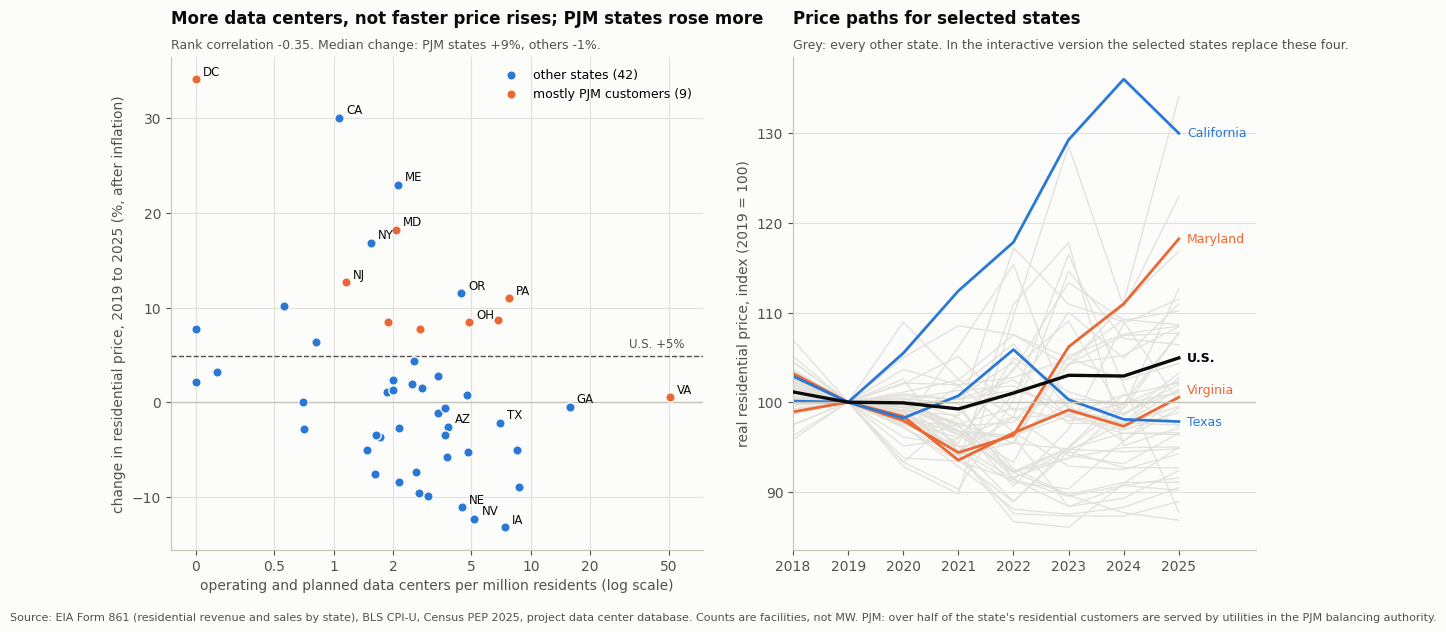

In [4]:
ZERO = 0.2                      # where states with no data centers sit on the log axis
TICKS = [ZERO, 0.5, 1, 2, 5, 10, 20, 50]
TICKL = ["0", "0.5", "1", "2", "5", "10", "20", "50"]
t["x"] = t.dc_per_m.where(t.dc_per_m > 0, ZERO)
LABEL = ["VA", "DC", "CA", "MD", "NJ", "ME", "OR", "NY", "PA", "OH", "GA", "TX", "IA", "NV", "NE", "AZ"]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw=dict(width_ratios=[1.15, 1], wspace=0.18))
for flag, col, lab in [(False, BLUE, "other states"), (True, ORANGE, "mostly PJM customers")]:
    g = t[t.pjm == flag]
    ax.scatter(g.x, g.price_change_pct, s=46, color=col, edgecolors=SURF, linewidths=1, label=f"{lab} ({len(g)})", zorder=3)
for st in LABEL:
    r = t.loc[st]
    ax.annotate(st, (r.x, r.price_change_pct), xytext=(5, 3), textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_xticks(TICKS, TICKL); ax.minorticks_off()
ax.axhline(0, color=AXIS, lw=1); ax.axhline(us_idx[END] - 100, color=INK2, lw=1, ls="--")
ax.text(60, us_idx[END] - 100 + 0.8, f"U.S. {us_idx[END] - 100:+.0f}%", ha="right", fontsize=8.5, color=INK2)
ax.set_xlim(0.15, 75)
ax.set_xlabel("operating and planned data centers per million residents (log scale)")
ax.set_ylabel(f"change in residential price, {BASE} to {END} (%, after inflation)")
ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.set_title("More data centers, not faster price rises; PJM states rose more", loc="left", fontsize=12, fontweight="bold", pad=24)
ax.text(0, 1.01, f"Rank correlation {rho_all:.2f}. Median change: PJM states {t[t.pjm].price_change_pct.median():+.0f}%, others {t[~t.pjm].price_change_pct.median():+.0f}%.",
        transform=ax.transAxes, fontsize=9, color=INK2, va="bottom")

HL = {"VA": ORANGE, "MD": ORANGE, "CA": BLUE, "TX": BLUE}
yrs = idx.columns.values
for st in idx.index:
    if st not in HL: bx.plot(yrs, idx.loc[st], color=GRID, lw=0.9, zorder=1)
bx.plot(yrs, us_idx.loc[yrs], color=INK, lw=2.4, zorder=3)
bx.annotate("U.S.", (yrs[-1], us_idx[END]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, fontweight="bold")
ends = {}
for st, col in HL.items():
    bx.plot(yrs, idx.loc[st], color=col, lw=2, zorder=2); ends[st] = idx.loc[st, END]
pos = {}
for st, v in sorted(ends.items(), key=lambda kv: kv[1]):
    pos[st] = max(v, max(pos.values(), default=-99) + 3.5)
for st, v in ends.items():
    bx.annotate(names[st], (yrs[-1], v), xytext=(yrs[-1] + 0.15, pos[st]), textcoords="data", va="center", fontsize=9, color=HL[st])
bx.axhline(100, color=AXIS, lw=1)
bx.set_xlim(yrs[0], yrs[-1] + 1.4); bx.set_xticks(yrs)
bx.set_ylabel(f"real residential price, index ({BASE} = 100)")
bx.grid(axis="y", color=GRID, lw=0.8); bx.set_axisbelow(True)
for sp in ["top", "right"]: bx.spines[sp].set_visible(False)
bx.set_title("Price paths for selected states", loc="left", fontsize=12, fontweight="bold", pad=24)
bx.text(0, 1.01, "Grey: every other state. In the interactive version the selected states replace these four.",
        transform=bx.transAxes, fontsize=9, color=INK2, va="bottom")
fig.text(0.01, 0.0, "Source: EIA Form 861 (residential revenue and sales by state), BLS CPI-U, Census PEP 2025, project data center database. "
         "Counts are facilities, not MW. PJM: over half of the state's residential customers are served by utilities in the PJM balancing authority.",
         fontsize=8, color=INK2)
fig.savefig(ROOT / "images" / "prototype_e_price_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

## Interactive prototype (brush the scatter, see the price lines)
Drag a box or lasso on the scatter to select states; their price lines are drawn on the right next to the U.S. average. Click a single dot to add or remove it. Double click the scatter to clear.
The linking runs in JavaScript, so open `sgarimella/prototype_e_price_scatter.html` in a browser. The copy shown in the notebook is not linked.

In [5]:
import json, plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=2, column_widths=[0.52, 0.48], horizontal_spacing=0.09,
                    subplot_titles=("States: data centers vs price change", "Real residential price, 2019 = 100"))
order = list(idx.index)
for flag, col, lab in [(False, BLUE, "other states"), (True, ORANGE, "mostly PJM customers")]:
    g = t[t.pjm == flag]
    fig.add_trace(go.Scatter(x=g.x, y=g.price_change_pct, mode="markers+text", name=lab, text=g.index, textposition="top center",
        textfont=dict(size=9, color=INK2), customdata=g.reset_index()[["state", "state_name", "dc_live", "dc_operating", "price_2019", "price_2025"]].values.tolist(),
        marker=dict(size=10, color=col, line=dict(width=1, color=SURF)),
        selected=dict(marker=dict(opacity=1)), unselected=dict(marker=dict(opacity=0.25)),
        hovertemplate="<b>%{customdata[1]}</b><br>%{customdata[2]} data centers (%{customdata[3]} operating)<br>"
                      "%{x:.1f} per million residents<br>%{customdata[4]:.1f} to %{customdata[5]:.1f} cents/kWh (2025 $)<br>"
                      "%{y:+.1f}% after inflation<extra></extra>"), 1, 1)
fig.add_hline(y=us_idx[END] - 100, line=dict(color=INK2, dash="dash", width=1), row=1, col=1,
              annotation_text=f"U.S. {us_idx[END] - 100:+.0f}%", annotation_position="bottom right", annotation_font_color=INK2)
yrs = [int(y) for y in idx.columns]
for st in order:   # grey context lines
    fig.add_trace(go.Scatter(x=yrs, y=idx.loc[st].round(1).tolist(), mode="lines", name=st, showlegend=False,
        line=dict(color=GRID, width=1), hovertemplate=f"<b>{names[st]}</b> %{{x}}: %{{y:.0f}}<extra></extra>"), 1, 2)
HI0 = len(fig.data)
for st in order:   # highlight layer, shown only for brushed states
    col = ORANGE if t.loc[st, "pjm"] else BLUE
    fig.add_trace(go.Scatter(x=yrs, y=idx.loc[st].round(1).tolist(), mode="lines+text", name=st + " (selected)", showlegend=False,
        visible=False, line=dict(color=col, width=2.5), text=[""] * (len(yrs) - 1) + [st], textposition="middle right",
        textfont=dict(color=col, size=11), hovertemplate=f"<b>{names[st]}</b> %{{x}}: %{{y:.0f}}<extra></extra>"), 1, 2)
fig.add_trace(go.Scatter(x=yrs, y=us_idx.loc[yrs].round(1).tolist(), mode="lines", name="U.S. average", line=dict(color=INK, width=3),
                         hovertemplate="<b>U.S.</b> %{x}: %{y:.0f}<extra></extra>"), 1, 2)
fig.update_xaxes(type="log", tickvals=TICKS, ticktext=TICKL, title="operating and planned data centers per million residents (log)",
                 gridcolor=GRID, row=1, col=1)
fig.update_yaxes(title="price change 2019-2025 (%, after inflation)", gridcolor=GRID, zeroline=True, zerolinecolor=AXIS, row=1, col=1)
fig.update_xaxes(dtick=1, range=[2017.7, 2025.8], gridcolor=GRID, row=1, col=2)
fig.update_yaxes(gridcolor=GRID, row=1, col=2)
fig.update_layout(height=600, paper_bgcolor=SURF, plot_bgcolor=SURF, dragmode="select", clickmode="event",
                  margin=dict(l=60, r=30, t=90, b=60), legend=dict(x=0.5, xanchor="right", y=1.0, bgcolor="rgba(252,252,251,0.85)"),
                  title=dict(text="Brush states to compare their price paths with the U.S. average", x=0.01))
fig.add_annotation(text=f"Rank correlation {rho_all:.2f}. Drag a box to select states, click a dot to add or remove it, double click to clear. "
                        "Sources: EIA-861, BLS CPI-U, Census PEP 2025, project data center database.",
                   xref="paper", yref="paper", x=0, y=-0.13, showarrow=False, font=dict(size=10, color=INK2), xanchor="left")

# Brushing: show the highlight line for each selected state. Only restyles visibility, so the selection itself is untouched.
post = """
var gd = document.getElementById('{plot_id}');
var HI0 = %d, ORDER = %s;
var HI = ORDER.map(function (_, k) { return HI0 + k; });
var cur = new Set();
function show(states) {
  cur = states;
  Plotly.restyle(gd, {visible: ORDER.map(function (s) { return states.has(s); })}, HI);
}
function scatterStates(points) {
  return points.filter(function (p) { return p.data.xaxis === 'x'; }).map(function (p) { return p.customdata[0]; });
}
gd.on('plotly_selected', function (ev) {
  if (!ev || !ev.points) return;
  show(new Set(scatterStates(ev.points)));
});
var lastClick = 0;
gd.on('plotly_click', function (ev) {   // click a dot to add or remove that state
  var hit = scatterStates(ev.points); if (!hit.length) return;
  lastClick = Date.now();
  var next = new Set(cur); if (next.has(hit[0])) next.delete(hit[0]); else next.add(hit[0]);
  show(next);
});
// A click on a dot also clears the box, so only clear the lines when no dot click came with it (double click on empty space).
gd.on('plotly_deselect', function () {
  setTimeout(function () { if (Date.now() - lastClick > 400) show(new Set()); }, 200);
});
""" % (HI0, json.dumps(order))
fig.write_html(ROOT / "sgarimella" / "prototype_e_price_scatter.html", include_plotlyjs=True, post_script=post,
               config={"displayModeBar": False})
fig.show()

## Reading so far
- At the state level the relationship runs the other way from the worry: the rank correlation is about -0.35. Of the eight states with the most data centers per resident, six had flat or falling real prices (Virginia, Georgia, North Dakota, Wyoming, Iowa, Texas). The other two, Pennsylvania (+11%) and West Virginia (+9%), are PJM states. Cheap power may be part of why developers build in the flat or falling states, but this data does not test that. The biggest increases (DC, California, Maine, Maryland, New York) are in states with few data centers.
- Virginia, with by far the most data centers per resident, is flat after inflation (+0.6%).
- What does stand out is the grid: states mostly served by PJM utilities had a median real increase of about +9%, against about -1% for the rest. That points to a region-wide cost more than a local one, which is what prototype F looks at.

Next steps: swap the x axis to MW where coverage allows, try utility-level prices (`proto_data.utility_price_table`) to see whether utilities that serve data center counties differ from neighbors in the same state, and add 2026 once EIA posts it.